# CV - Image Classification - Segmentation - Autoencoders

Note that this lab has three levels: basic, regular and advanced.


Doing the **basic** part earns you a grade of 5.5-6.0.

Doing the **regular** part earns you a max grade of 8.0.

Doing the **advanced** part earns you a max grade of 10.0.

Please return a Jupyter notebook as a submission in Canvas, to make the grading easier for us.

## Basic Level

Exploring the basic concepts discussed in the lecture.


In [1]:
import numpy as np
import re
import keras
from sklearn.model_selection import train_test_split
from keras.datasets import cifar10, mnist, cifar100
from keras.models import Sequential
from keras.layers import Input, Dense, Activation,BatchNormalization, Flatten, Conv2D, MaxPooling2D
# from keras.utils import np_utils ## DEPRECATED
from keras.utils import to_categorical
# from keras.utils import np_
from sklearn import preprocessing
import matplotlib.pyplot as plt
from keras.applications import EfficientNetV2S, ResNet50, vgg16
from keras.utils import to_categorical 
import pandas as pd
import numpy as np
from PIL import Image
import os
import os.path
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.metrics import accuracy_score
from matplotlib import pyplot as plt
import keras
from keras.metrics import MeanIoU
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.utils import to_categorical 
import random
from sklearn.metrics import confusion_matrix
from scipy.special import softmax
from keras.layers import LeakyReLU
from sklearn.utils import shuffle
from keras.layers import  Input, Dense, BatchNormalization, Conv2D, Dropout, Conv2DTranspose, Concatenate
from keras import layers
from keras.layers import Input, Dense, Activation,BatchNormalization, Flatten, Conv2D, MaxPooling2D
from keras.models import Model
from keras.preprocessing import image
import keras.backend as K
from skimage import io
from skimage.util import random_noise
from skimage.transform import rotate, AffineTransform,warp

from keras.metrics import BinaryIoU



In [2]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


## Classification and Transfer Learning

### Exercise 1

In this exercise, we will work with the CIFAR100 dataset. 

The dataset can be import from keras datasets directly. No preprocessing is needed, you can directly use it to learn a model.

The CIFAR100 dataset has a 100 classes, each with 600 examples.

a. Let's load the dataset from keras

In [3]:
(train_X, train_y), (test_X, test_y)=cifar100.load_data()

In [4]:
train_y=to_categorical(train_y)

In [5]:
test_y=to_categorical(test_y)

b. Let's create a CNN model to learn to classify the data.

Create your model using the functional API.

In [6]:
#Your code goes here
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(8, (3, 3), padding='same', activation='relu')(inputs) ## padding='same' keeps the output with 32x32 dimension
x = layers.Conv2D(16, (3, 3), padding='same', activation='relu')(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(100, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_basic')
model.summary()

Model: "cnn_basic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │         6,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,056,532 (4.03 MB)

 Trainable params: 1,056,532 (4.03 MB)

 Non-trainable params: 0 (0.00 B)

c. compile and fit the model to the data.

This process might take too long, set the number of epochs to some low value. The goal of this part is to show that this classification problem (100 classes) is complex.

In [7]:
#Your code goes here
model.compile(optimizer="adam", loss='categorical_crossentropy', metrics=['accuracy'])

In [8]:
print(train_y.shape)
print(train_X.shape)

(50000, 100)
(50000, 32, 32, 3)


In [9]:
model.fit(train_X, train_y, epochs=5, batch_size=64, validation_data=(test_X, test_y))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.0087 - loss: 6.6409 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.0091 - loss: 4.6057 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.0088 - loss: 4.6057 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.0088 - loss: 4.6057 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.0082 - loss: 4.6057 - val_accuracy: 0.0100 - val_loss: 4.6052


### Exercise 2

The model trained on CIFAR100 is probably not giving the best results you can achieve. 

Let's train the same model on CIFAR10, a version of CIFAR with only 10 classes instead of a 100.

In [10]:
(train_X, train_y), (test_X, test_y)=cifar10.load_data()

In [11]:
train_y=to_categorical(train_y)
test_y=to_categorical(test_y)

a. Recreate your basic model here, compile it and fit it to the data.

In [12]:
#Your code goes here
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(8, (3, 3), padding='same', activation='relu')(inputs) ## padding='same' keeps the output with 32x32 dimension
x = layers.Conv2D(16, (3, 3), padding='same', activation='relu')(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(10, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs, name='cnn_basic')
model.summary()

model.compile(optimizer="adam", loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(train_X, train_y, epochs=5, batch_size=64, validation_data=(test_X, test_y))

Model: "cnn_basic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,050,682 (4.01 MB)

 Trainable params: 1,050,682 (4.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.1536 - loss: 5.7752 - val_accuracy: 0.1669 - val_loss: 2.2196
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.2271 - loss: 2.1503 - val_accuracy: 0.2741 - val_loss: 2.0749
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.2893 - loss: 1.9745 - val_accuracy: 0.3015 - val_loss: 1.9503
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.3380 - loss: 1.8199 - val_accuracy: 0.3493 - val_loss: 1.8182
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.3945 - loss: 1.6643 - val_accuracy: 0.4058 - val_loss: 1.6895


### Exercise 3

Our basic CNN model does better on the CIFAR10 dataset than it did on the CIFAR100. 

The CIFAR10 is less comples, distinguishing 10 classes is a lot less complex than distinguishing a 100.

We can use transfer learning to solve this complex problem. We'll reuse the ResNet50 pretrained model from Keras, and adapt it to work on the CIFAR100.

a. Load Resnet50 from keras. Use the **imagenet** weights.

You can refer to keras to learn how to use this pretrained model, [here](https://keras.io/api/applications/resnet/).

In [13]:
#Your code goes here
pretrained = ResNet50(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
# pretrained.l

In [14]:
#Showing the layers names and inputs
for i, layer in enumerate(pretrained.layers):
    print(i, layer.name, layer.output.shape)

0 input_layer_2 (None, 32, 32, 3)
1 conv1_pad (None, 38, 38, 3)
2 conv1_conv (None, 16, 16, 64)
3 conv1_bn (None, 16, 16, 64)
4 conv1_relu (None, 16, 16, 64)
5 pool1_pad (None, 18, 18, 64)
6 pool1_pool (None, 8, 8, 64)
7 conv2_block1_1_conv (None, 8, 8, 64)
8 conv2_block1_1_bn (None, 8, 8, 64)
9 conv2_block1_1_relu (None, 8, 8, 64)
10 conv2_block1_2_conv (None, 8, 8, 64)
11 conv2_block1_2_bn (None, 8, 8, 64)
12 conv2_block1_2_relu (None, 8, 8, 64)
13 conv2_block1_0_conv (None, 8, 8, 256)
14 conv2_block1_3_conv (None, 8, 8, 256)
15 conv2_block1_0_bn (None, 8, 8, 256)
16 conv2_block1_3_bn (None, 8, 8, 256)
17 conv2_block1_add (None, 8, 8, 256)
18 conv2_block1_out (None, 8, 8, 256)
19 conv2_block2_1_conv (None, 8, 8, 64)
20 conv2_block2_1_bn (None, 8, 8, 64)
21 conv2_block2_1_relu (None, 8, 8, 64)
22 conv2_block2_2_conv (None, 8, 8, 64)
23 conv2_block2_2_bn (None, 8, 8, 64)
24 conv2_block2_2_relu (None, 8, 8, 64)
25 conv2_block2_3_conv (None, 8, 8, 256)
26 conv2_block2_3_bn (None, 8, 8, 2

b. Make sure all (or at least some) layers in the pretrained ResNet-50 are not trainable.

In [15]:
#Your code goes here

for _, layer in enumerate(pretrained.layers):
    layer.trainable=False




c. Add an output layer adequate to the task we have (predicting a 100 classes).

In [16]:
#Your code goes here

model = Sequential()
model.add(pretrained)
model.add(Flatten())
model.add(Dense(16, activation='relu'))
model.add(Dense(100, activation='softmax'))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │        32,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │         1,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,622,196 (90.11 MB)

 Trainable params: 34,484 (134.70 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

d. Compile and train your model.

In [17]:
#Your code goes here
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [18]:
(train_X, train_y), (test_X, test_y) = cifar100.load_data()
train_y = to_categorical(train_y)
test_y = to_categorical(test_y)

In [19]:
model.fit(train_X, train_y, epochs=1)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 58s 36ms/step - accuracy: 0.1319 - loss: 3.7266


As you train the model longer, the model will improve its accuracy.

The dataset is balanced, so "accuracy" is an adequate performance metric here.

### Exercise 4

ResNet50 shows that it can help with the CIFAR100 problem.

Let's now check whether it will allow us improve our predictions on the Breast Cancer dataset we worked with in the fist lab.

a. First, reload your images from the same dataset as before. 

Load the images in a data structure, and their correponding labels in another. Make sure that the images are aligned with their labels.

Notice that the dataset has now the images used in the first lab and their corresponding masks. We will need the masks for the segmentation exercises. Do not use them for this classification problem.

In [4]:
#Your code goes here
import os
folder='assignment_DS'
images = []
labels = []

for subdir in os.listdir(folder):
    for file in os.listdir(os.path.join(folder, subdir)):
        if '_mask' in file:
            continue
        filepath = os.path.join(folder, subdir, file)
        im = Image.open(filepath)
        images.append(im)
        labels.append(subdir)

b. Resize our images. Choose The size you wish.

In [50]:
#Your code goes here

for idx in tqdm(range(len(images))):
    images[idx] = images[idx].resize((64, 64))


100%|██████████| 766/766 [00:03<00:00, 193.02it/s]


c. Convert the images to numpy arrays.

In [51]:
#Your code goes here
np_images = np.array([np.array(im) for im in images])
print(np_images.shape)

(766, 64, 64, 3)


d. Rescale the images.

In [52]:
#Your code goes here
np_images = keras.applications.resnet50.preprocess_input(np_images.astype('float32'))


e. We'll work on the multiclass classification problem. Create a **y** vector with the labels 0 for **normal**, 1 for **benign** and 2 for **malignant**.

In [53]:
mapping = {'malignant': 2, 'benign': 1, 'normal' : 0}
label_encoded = [mapping[l] for l in labels]
y = to_categorical(label_encoded)

f. Let's now create a train and test set from our data.

In [54]:
train_X, test_X, train_y, test_y = train_test_split(np_images, y, test_size=0.2, shuffle=True, random_state=4)

g. Create a model based on the ResNet50 model and see whether the results of the classification improve compared to the model you developed in the previous lab.

Note that ResNet50 might not be the best pretrained model for all tasks, keras offers other pretrained models. You can try any one of them.

In [55]:
###Define and compile the model
pretrained = ResNet50(weights='imagenet', include_top=False, input_shape=(64, 64, 3))
pretrained.trainable = False
chosen_model = Sequential()
chosen_model.add(pretrained)
chosen_model.add(Flatten())
chosen_model.add(Dense(16, activation='relu'))
chosen_model.add(Dropout(0.3))
chosen_model.add(Dense(3, activation='softmax'))
chosen_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [56]:
###Train the model

history = chosen_model.fit(train_X, train_y, validation_split=0.1, epochs=30, batch_size=32)


Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 188ms/step - accuracy: 0.4564 - loss: 1.6481 - val_accuracy: 0.5323 - val_loss: 0.7991
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step - accuracy: 0.5309 - loss: 0.8274 - val_accuracy: 0.5323 - val_loss: 0.8651
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.5509 - loss: 0.8081 - val_accuracy: 0.6774 - val_loss: 0.8237
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 178ms/step - accuracy: 0.5545 - loss: 0.7313 - val_accuracy: 0.6452 - val_loss: 0.7426
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 171ms/step - accuracy: 0.5691 - loss: 0.7012 - val_accuracy: 0.6129 - val_loss: 0.7752
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 170ms/step - accuracy: 0.6636 - loss: 0.6535 - val_accuracy: 0.6290 - val_loss: 0.8636
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - accuracy: 0.7291 - loss: 0.6331 - val_accuracy: 0.7097 - val_loss: 0.7083
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.7527 - loss: 0.5480 - val_accuracy: 0.

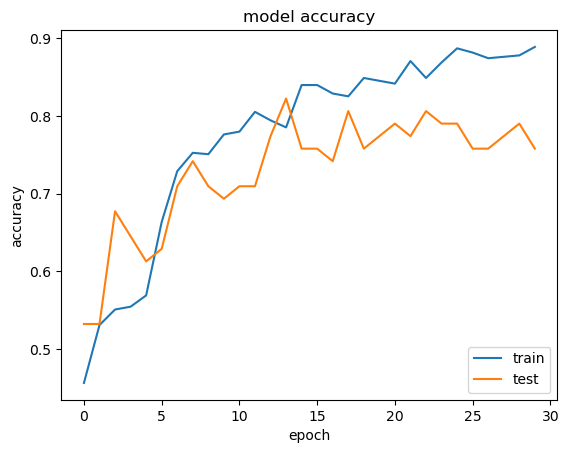

In [57]:
###Plot the training acc and val_acc
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc="lower right")
plt.show()

In [58]:
###Check its accuracy on the test set
test_loss, test_acc = chosen_model.evaluate(test_X, test_y)

print(f"The accuracy on test is {test_acc * 100:.1f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - accuracy: 0.8377 - loss: 0.7237
The accuracy on test is 83.8%


## Image Segmentation
Let's now shift to work on image segmentation. 
We have discussed the topic in the lecture, and said that this is a supervised learning problem in which the model learns a mapping between the image and its mask.

### Exercise 5

Let's load the images from our dataset again, this time with their corresponding masks as well.

Make an X data structure with the images, and a Y data structure with the masks.

Check that the images are aligned with their masks, otherwise the training won't work.

In [5]:
#Your code goes here

X = []
Y = []
for listdir in os.listdir(folder):
    subpath = os.path.join(folder, listdir)
    if not os.path.isdir(subpath):
        continue
    for file in os.listdir(subpath):
        if '_mask' in file:
            continue
        filename = file[:-4]
        mask_file = filename + '_mask.png'

        if not os.path.exists(os.path.join(subpath, mask_file)):
            mask_file = filename + '_mask_1.png'

        X.append(Image.open(os.path.join(subpath, file)))
        Y.append(Image.open(os.path.join(subpath, mask_file)))

print(len(Y) == len(X))

True


### Exercise 6

Convert both images and masks from RGB mode to grayscale, and resize both to a size you see fit.

In [6]:
#Your code goes here
#Your code goes here
for idx in tqdm(range(len(X))):
    X[idx] = X[idx].convert("L").resize((128, 128))
    Y[idx] = Y[idx].convert("L").resize((128, 128), Image.NEAREST)
    

100%|██████████| 766/766 [00:08<00:00, 94.45it/s] 


### Exercise 7

Convert your images to numpy arrays.
The shape of the masks should be (ne=766, height, width), same goes for the images.

In [7]:
#Your code goes here
print(len(X))
np_X = np.array([np.array(img) for img in X])
np_Y = np.array([np.array(img) for img in Y])

print(np_X.shape)
print(np_Y.shape)

766
(766, 128, 128)
(766, 128, 128)


### Exercise 8
We have 766 examples with their corresponding masks, our semantic segmentation model will need more to be able to yield better results.

Apply some data augmentation techniques to generate new data.

Keep in mind that the masks need to be subjected to the same transformations you apply to the images. (if you rotate an image by 25 degrees, the mask should also be rotated with the same value). 

Creating 5 images from each image should give you around 3830 data points with their masks, which should be enough.

Check Scikit-Image for data augmentation functions that you can use, [here](https://scikit-image.org/docs/dev/api/skimage.transform.html)

In [8]:
#Your code goes here
    
def augment(img, mask):
    angle = np.random.uniform(-25, 25)
    tx, ty = np.random.uniform(-10, 10, size=2)
    flip = np.random.rand() < 0.5


    img = rotate(img, angle, mode='edge')

    tf = AffineTransform(translation=(tx, ty))
    img = warp(img, tf.inverse, mode='edge')

    mask = rotate(mask, angle, mode='edge', order=0)
    mask = warp(mask, tf.inverse, mode='edge', order=0)

    if flip:
        img = np.fliplr(img)
        mask = np.fliplr(mask)
    return img, mask

X_scaled = np_X.astype('float') / 255.0
Y_scaled = (np_Y > 127).astype('float32')

images = [x for x in X_scaled]
masks = [y for y in Y_scaled]

for i in tqdm(range(len(X_scaled))):
    for _ in range(4):
        a_img, a_mask = augment(X_scaled[i], Y_scaled[i])
        images.append(a_img)
        masks.append(a_mask)

images = np.array(images)
masks = np.array(masks)

print(images.shape, masks.shape)
    

100%|██████████| 766/766 [00:14<00:00, 53.40it/s]


(3830, 128, 128) (3830, 128, 128)


Make sure you create a test set as well.

In [9]:
train_X, test_X, train_y, test_y = train_test_split(images, masks, test_size=0.25, shuffle=True, random_state=42)

### Exercise 9

Defining your U-NET architecture below. 

Make sure to use Keras' functional API.

In [10]:
train_X.shape

(2872, 128, 128)

In [11]:
#Your code goes here
def encoder_block(inputs, num_filters):
    x = Conv2D(num_filters, 3, padding='same', activation='relu')(inputs)
    x = Conv2D(num_filters, 3, padding='same', activation='relu')(x)
    p = MaxPooling2D((2, 2), strides=2)(x)
    return x, p   

In [12]:
#Your code goes here
def decoder_block(inputs, skip, num_filters):
    x = Conv2DTranspose(num_filters, kernel_size=(2, 2), strides = 2, padding='same')(inputs)
    x = Concatenate()([x, skip])
    x = Conv2D(num_filters, 3, padding='same', activation='relu')(x)
    x = Conv2D(num_filters, 3, padding='same', activation='relu')(x)

    return x


In [13]:
def unet_model(input_shape=(128, 128, 1), n_classes=1):
    inputs = Input(shape=input_shape)

    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    b1 = Conv2D(1024, 3, padding='same', activation='relu')(p4)
    b2 = Conv2D(1024, 3, padding='same', activation='relu')(b1)

    d1 = decoder_block(b2, s4, 512)
    d2 = decoder_block(d1, s3, 256)
    d3 = decoder_block(d2, s2, 128)
    d4 = decoder_block(d3, s1, 64)

    outputs = Conv2D(n_classes, 1, activation='sigmoid')(d4)

    return Model(inputs, outputs, name='unet')


In [14]:
#Your code goes here

model = unet_model()
model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,030,593 (118.37 MB)

 Trainable params: 31,030,593 (118.37 MB)

 Non-trainable params: 0 (0.00 B)

### Exercise 10

Compile and train your model. 

This might take quite some time if you're not training on a GPU.

Use the university's Jupyter environment [here](https://jupyter.utwente.nl/) or refer to Google Colab. 

In [ ]:
#Your code goes here

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", BinaryIoU(target_class_ids=[1], threshold=0.5, name="iou")],)
history = model.fit(train_X, train_y, batch_size=16, epochs=15, validation_split=0.1)


Epoch 1/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 108s 414ms/step - accuracy: 0.9166 - iou: 0.0124 - loss: 0.2935 - val_accuracy: 0.9259 - val_iou: 0.0000e+00 - val_loss: 0.2599
Epoch 2/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 35s 216ms/step - accuracy: 0.9214 - iou: 0.0037 - loss: 0.2562 - val_accuracy: 0.9259 - val_iou: 0.0000e+00 - val_loss: 0.2156
Epoch 3/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 35s 217ms/step - accuracy: 0.9234 - iou: 0.0363 - loss: 0.2122 - val_accuracy: 0.9358 - val_iou: 0.2479 - val_loss: 0.1861
Epoch 4/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 35s 215ms/step - accuracy: 0.9285 - iou: 0.1575 - loss: 0.1992 - val_accuracy: 0.9312 - val_iou: 0.1574 - val_loss: 0.1916
Epoch 5/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 35s 217ms/step - accuracy: 0.9345 - iou: 0.2609 - loss: 0.1840 - val_accuracy: 0.9306 - val_iou: 0.3316 - val_loss: 0.1913
Epoch 6/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 35s 218ms/step - accuracy: 0.9419 - iou: 0.3474 - loss: 0.1650 - val_accuracy: 0.9398 - val_iou: 0.4186 - val_loss: 0.1643
Epoch 7/15
16

30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 329ms/step - accuracy: 0.9581 - iou: 0.5681 - loss: 0.1147


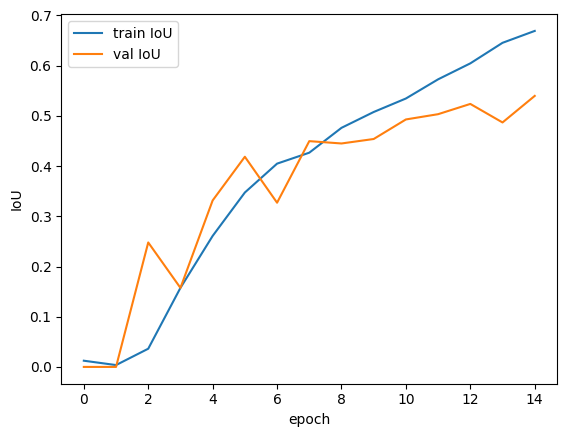

In [16]:
model.evaluate(test_X, test_y)   # prints loss, accuracy, iou on the test set

plt.plot(history.history["iou"], label="train IoU")
plt.plot(history.history["val_iou"], label="val IoU")
plt.xlabel("epoch"); plt.ylabel("IoU"); plt.legend(); plt.show()


### Exercise 10
Make the predictions based on your trained model, and show for a few examples (3 should be enough), the difference between what your model predicted and the ground truth mask.

30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 151ms/step


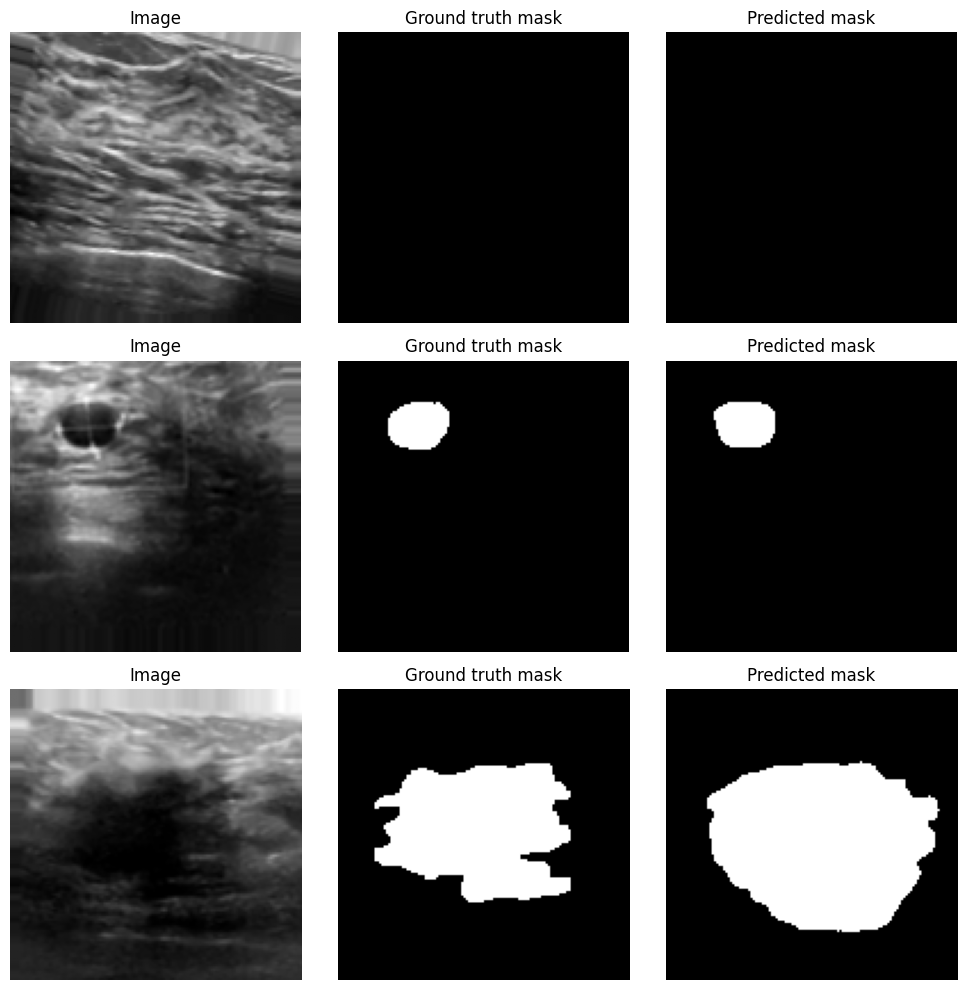

In [17]:
#Your code goes here
preds = model.predict(test_X)

preds_bin = (preds > 0.5).astype('float32') 

idx = [11, 1, 2]
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, i in enumerate(idx):
    axes[row, 0].imshow(test_X[i].squeeze(), cmap='gray')
    axes[row, 0].set_title('Image')
    axes[row, 1].imshow(test_y[i].squeeze(), cmap='gray')
    axes[row, 1].set_title('Ground truth mask')
    axes[row, 2].imshow(preds_bin[i].squeeze(), cmap='gray')
    axes[row, 2].set_title('Predicted mask')
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()


## Denoising Autoencoders
### Exercise 11
Let's now practice autoencoder architectures that we discussed in the lecture.

We'll focus on denoising autoencoders.

First, let's load our dataset, and apply some noise to the images. 

You can apply any type of noise you want, refer to [here](https://scikit-image.org/docs/stable/api/skimage.util.html#skimage.util.random_noise)

In [11]:
#Your code goes here
images = []
for listdir in os.listdir(folder):
    subpath = os.path.join(folder, listdir)
    if not os.path.exists(subpath):
        continue
    for file in os.listdir(subpath):
        if '_mask' in file:
            continue
        im = Image.open(os.path.join(subpath, file)).convert("L").resize((128, 128))
        images.append(im)

X = np.array(images).astype('float') / 255.0
noised_X = np.array([random_noise(im, mode='gaussian', var=0.01) for im in X])

print(X.shape)
print(noised_X.shape)


(766, 128, 128)
(766, 128, 128)


In [12]:
train_X, test_X, train_y, test_y = train_test_split(noised_X, X, test_size=0.25, shuffle=True, random_state=42)

### Exercise 13
Create your encoder architecture.

This should output the latent space.

In [13]:
#Your code goes here

def build_encoder(input_shape=(128,128, 1)):
    inputs = Input(shape=input_shape)
    x = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(64, 3, activation='relu', padding='same')(x)
    x = MaxPooling2D((2,2))(x)
    x = Conv2D(32, 3, activation='relu', padding='same')(x)
    x = MaxPooling2D((2,2))(x)

    return Model(inputs, x, name='encoder')

build_encoder().summary()

    

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,280 (145.62 KB)

 Trainable params: 37,280 (145.62 KB)

 Non-trainable params: 0 (0.00 B)

### Exercise 14
Create your decoder architecture.

This should input the latent space.

In [14]:
#Your code goes here

def build_decoder(input_shape=(16, 16, 32)):
    input = Input(shape=input_shape)

    x = Conv2DTranspose(16, 3, strides=2, padding='same', activation='relu')(input)
    x = Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(x)
    x = Conv2DTranspose(16, 3, strides=2, padding='same', activation='relu')(x)

    x = Conv2D(1, 3, padding='same', activation='sigmoid')(x)

    return Model(input, x, name='decoder')


build_decoder().summary()

    

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 32, 32, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 64, 64, 32)     │         4,640 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 128, 128, 16)   │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 128, 128, 1)    │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,033 (54.82 KB)

 Trainable params: 14,033 (54.82 KB)

 Non-trainable params: 0 (0.00 B)

### Exercise 15

Compile the autoencoder now that you have both components.

Train the autoencoder for a number of epochs of your choosing.

In [ ]:
#Your code goes here

encoder = build_encoder()
decoder = build_decoder()

input = Input(shape=(128, 128, 1))
autoencoder = Model(input, decoder(encoder(input)), name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse', metrics=['accuracy'])


history = autoencoder.fit(train_X, train_y,
                          epochs=30, batch_size=32, validation_split=0.1)


Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 183ms/step - loss: 0.0754 - val_loss: 0.0709
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - loss: 0.0620 - val_loss: 0.0525
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 258ms/step - loss: 0.0309 - val_loss: 0.0195
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 213ms/step - loss: 0.0170 - val_loss: 0.0152
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - loss: 0.0132 - val_loss: 0.0119
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 217ms/step - loss: 0.0094 - val_loss: 0.0078
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 230ms/step - loss: 0.0072 - val_loss: 0.0070
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 239ms/step - loss: 0.0067 - val_loss: 0.0067
Epoch 9/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - loss: 0.0064 - val_loss: 0.0064
Epoch 10/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 205ms/step - loss: 0.0062 - val_loss: 0.0063
Epoch 11/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step - loss: 0.0060 - val_loss: 0.0064
Epoch 12/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step

### Exercise 16

Use the model to denoise the images on your test set, and show a comparison of your model's work and the ground truth (3 samples will suffice).

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


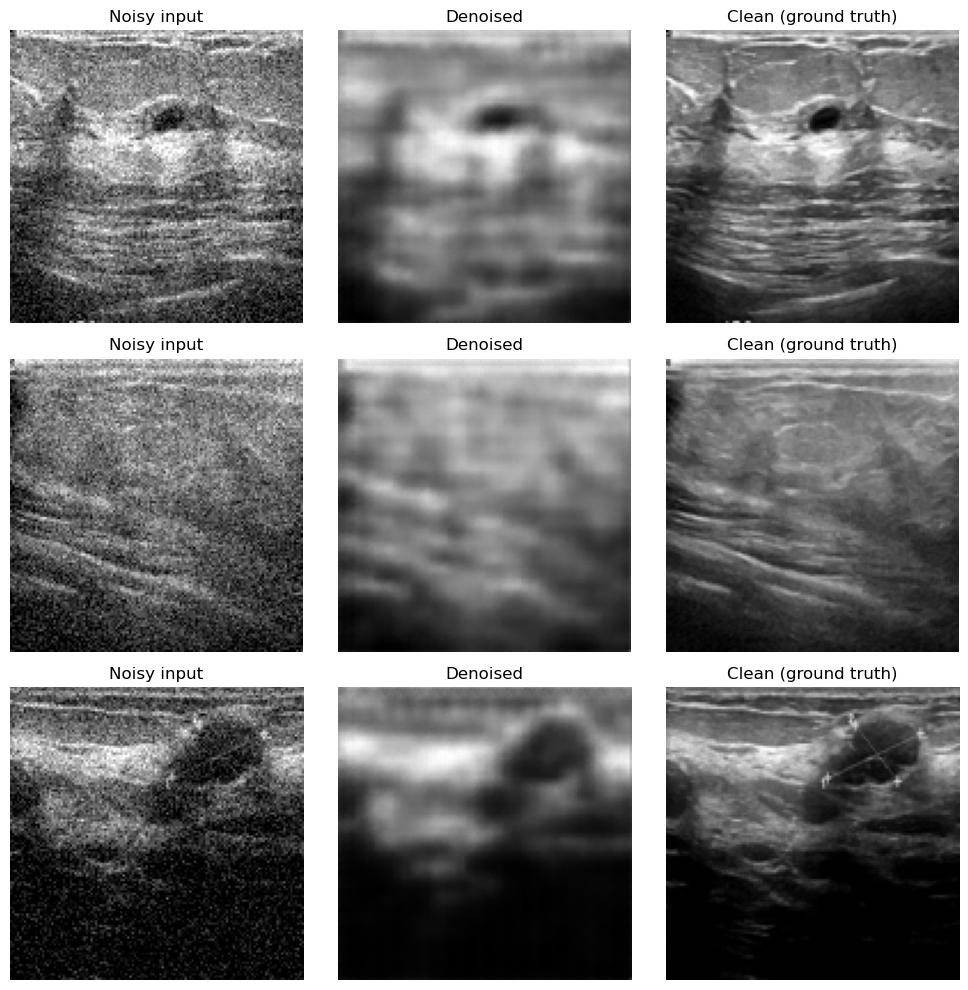

In [ ]:
#Your code goes here
preds = autoencoder.predict(test_X)

idx_top_three = [2, 6, 8]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, i in enumerate(idx_top_three):
    axes[row, 0].imshow(test_X[i].squeeze(), cmap='gray');  axes[row, 0].set_title('Noisy input')
    axes[row, 1].imshow(preds[i].squeeze(), cmap='gray');   axes[row, 1].set_title('Denoised')
    axes[row, 2].imshow(test_y[i].squeeze(), cmap='gray');  axes[row, 2].set_title('Clean (ground truth)')
    for ax in axes[row]: ax.axis('off')
plt.tight_layout()
plt.show()
    

This is the result we managed to get with a size of the picture reduced to 128x128px. 

On the other hand we also tried with bigger size of the picture (256x256px) and this is the result we got.

![Result image](./img.jpeg)

For the purpose of this notebook, in the last two exercises we will continue using the 128x128px format.

## Regular Part

In this part, we wish to explore how to deploy a model and make it accessible to users.

### Exercise 17

Save one of your classification models above in the  **h5** format. 

Create a web app (as simple as possible) where a user can upload an image, the app should then respond with its class.

In [60]:
## saving model

chosen_model.save("model.h5")

## Advanced Part

In this part, we wish to explore how to deploy a more complex model and make it accessible to users.

### Exercise 18

Save your denoising autoencoder model above in the  **h5** format. 

Create a web app (as simple as possible) where a user can upload an image, the app should then respond with its denoised version.

In [17]:
autoencoder.save('advanced_model.h5')